# Tarefa 1 — MLP com Backpropagation em Python

**Disciplina:** Redes Neurais Artificiais — Mestrado 2026/2 (Prof. Francisco Boldt)

## Enunciado

> Você deve implementar e testar um *Multi Layer Perceptron* (MLP) e comparar o resultado dele
> com o implementado no Scikit-Learn.
>
> O seu MLP deve aceitar parâmetros para definir a quantidade de camadas, assim como a quantidade
> de neurônios em cada camada e a função de ativação que será utilizada em cada camada.

## Organização do notebook

1. **Ambiente e reprodutibilidade** — registro das versões das bibliotecas, semente fixa e paleta visual.
2. **Funções de ativação** — hierarquia extensível (`Activation`) com $f(z)$ e produto vetor-Jacobiano
   (*VJP*) para `tanh`, `sigmoid`, `relu`, `leaky_relu`, `identity` e `softmax`.
3. **Funções auxiliares** — `include_bias` e `one_hot_encode` (compatíveis com as aulas 05c–05e).
4. **Classe `MLP`** — implementação do zero em NumPy, compatível com a API do Scikit-Learn
   (`BaseEstimator`, `ClassifierMixin`, `Pipeline`, `cross_validate`, `clone`, `predict_proba`),
   suportando:
   - qualquer quantidade de camadas e neurônios (`hidden_layer_sizes`, inclusive inteiro ou tupla vazia `()`);
   - uma função de ativação por camada (`activations`);
   - custo **MSE** (como nas aulas) ou **entropia cruzada + *softmax*** (como no `MLPClassifier`);
   - regularização **L2** (`alpha`, sem penalizar o *bias*), **momento** (`momentum`) e ***mini-batch*** (`batch_size`) opcionais.
5. **Verificação numérica do gradiente (*gradient checking*)** — testes automatizados com `assert`
   cobrindo 0 a 3 camadas ocultas, ativações mistas, *softmax* (com MSE e com entropia cruzada) e regularização L2.
6. **Experimentos e comparação pareada com `MLPClassifier`** em quatro problemas:
   XOR (com diagnóstico de *dying ReLU*), *Blobs* multiclasse (8 classes), Iris (CV estratificada 5×5)
   e Digits (64 atributos, 10 classes, curvas na mesma escala de *log-loss*, matriz de confusão e análise de erros).
7. **Síntese quantitativa e conclusões.**

### Extensões em relação ao código das aulas (`05c`, `05d`, `05e`)

| Aspecto | Código da aula (`05c`/`05d`/`05e`) | Esta implementação |
| :-- | :-- | :-- |
| Camadas e neurônios | `n_hidden=[...]` | `hidden_layer_sizes=(...)` ou `int` (mesma convenção do sklearn) |
| Ativação por camada | `np.tanh` fixa em todas as camadas | **uma ativação por camada** (`tanh`, `sigmoid`, `relu`, `leaky_relu`, `identity`, `softmax`) |
| Derivada / Jacobiano | `1 - tanh(z)**2` fixo no código | cada ativação fornece `derivative(z)` / `vjp(z, grad)` |
| Função de custo | MSE implícito (`y_pred - y`) | `mse` (com $f'_L(Z^{(L)})$ exato) **ou** `cross_entropy` (com saída `softmax`) |
| Gradiente | soma sobre as amostras | **média** sobre o lote (taxa de aprendizado independe de $n$) |
| Inicialização | `np.random.randn` (incluindo *bias*) | Xavier/Glorot $\sqrt{2/(\text{fan\_in}+\text{fan\_out})}$ ou He $\sqrt{2/\text{fan\_in}}$; *bias* zerado |
| Regularização / Otimização | GD *full-batch* puro | *full-batch* por padrão + `alpha` (L2), `momentum` e `batch_size` opcionais |
| Inferência e diagnóstico | apenas `predict` | `forward` sem efeitos colaterais, `decision_function`, `predict_proba`, `loss_curve_` |


## 1. Importações, ambiente e reprodutibilidade


In [1]:
import platform
import time
import warnings
from abc import ABC, abstractmethod

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import sklearn
from matplotlib.colors import BoundaryNorm, ListedColormap
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.datasets import load_digits, load_iris, make_blobs
from sklearn.exceptions import ConvergenceWarning, NotFittedError
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.validation import check_is_fitted

SEED = 42

# Paleta categórica validada para boa legibilidade e contraste em fundo claro.
PALETTE = [
    "#2a78d6",  # azul
    "#eb6834",  # laranja
    "#1baf7a",  # água
    "#eda100",  # amarelo
    "#e87ba4",  # magenta
    "#008300",  # verde
    "#6250d6",  # violeta
    "#e34948",  # vermelho
]

plt.rcParams.update(
    {
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
    }
)

# O MLPClassifier emite ConvergenceWarning quando fixamos max_iter para comparação pareada.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

print(
    f"Python {platform.python_version()} | "
    f"NumPy {np.__version__} | "
    f"scikit-learn {sklearn.__version__} | "
    f"Matplotlib {matplotlib.__version__} | "
    f"SEED={SEED}"
)

Python 3.13.18 | NumPy 2.5.4 | scikit-learn 1.9.1 | Matplotlib 3.11.2 | SEED=42


## 2. Funções de ativação

No *backpropagation*, cada camada $l$ aplica $A^{(l)} = f_l(Z^{(l)})$ no passo *forward* e propaga o
gradiente de $A^{(l)}$ para $Z^{(l)}$ no passo *backward* via produto vetor-Jacobiano (*VJP*):

- Para ativações **elemento a elemento** (`tanh`, `sigmoid`, `relu`, `leaky_relu`, `identity`), o
  Jacobiano é diagonal e o *VJP* se reduz a $\delta^{(l)} = \frac{\partial E}{\partial A^{(l)}} \odot f_l'(Z^{(l)})$.
- Para **`softmax`** (acoplada entre os neurônios da mesma amostra), o *VJP* usa o Jacobiano completo:
  $$\left(\frac{\partial s}{\partial z}\right)^\top g = s \odot \left(g - \sum_{k} g_k s_k\right), \quad s = \text{softmax}(z).$$

Seguindo o padrão orientado a objetos da `aula04a_cost_functions`, cada ativação é uma subclasse de
`Activation`. O atributo `low` define o valor-alvo da classe negativa no *one-hot* quando a ativação é
usada na camada de saída com MSE ($-1$ para ativações simétricas, $0$ para ativações não negativas).

| Nome | $f(z)$ | $f'(z)$ | Imagem | Alvo *one-hot* (MSE) |
| :-- | :-- | :-- | :-- | :--: |
| `tanh` | $\tanh(z)$ | $1 - \tanh^2(z)$ | $(-1, 1)$ | $\{-1, +1\}$ |
| `sigmoid` / `logistic` | $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ | $\sigma(z)\,(1 - \sigma(z))$ | $(0, 1)$ | $\{0, 1\}$ |
| `relu` | $\max(0, z)$ | $1$ se $z > 0$, senão $0$ | $[0, \infty)$ | $\{0, 1\}$ |
| `leaky_relu` | $z$ se $z > 0$, senão $0{,}01\,z$ | $1$ se $z > 0$, senão $0{,}01$ | $\mathbb{R}$ | $\{0, 1\}$ |
| `identity` / `linear` | $z$ | $1$ | $\mathbb{R}$ | $\{-1, +1\}$ |
| `softmax` | $\dfrac{e^{z_k}}{\sum_j e^{z_j}}$ | Jacobiano acoplado (*VJP*) | $(0, 1)^K$, $\sum = 1$ | $\{0, 1\}$ |


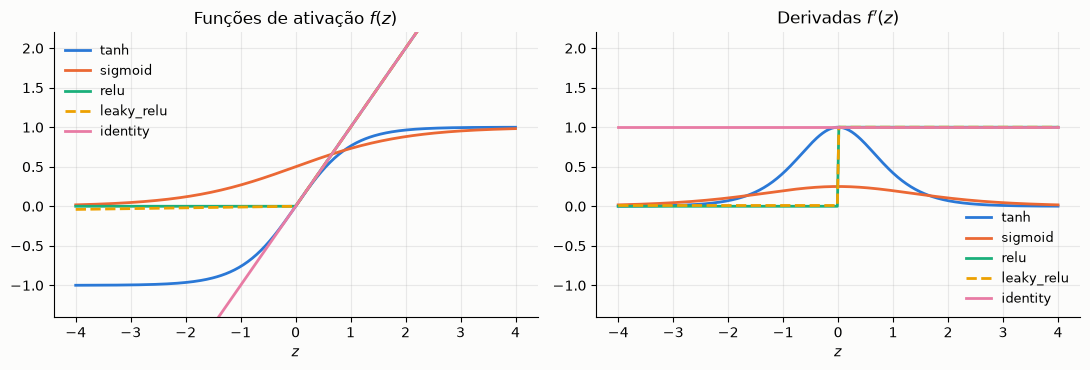

In [2]:
class Activation(ABC):
    """Interface base para funções de ativação."""

    low: float = -1.0
    is_relu_like: bool = False

    @abstractmethod
    def function(self, z: np.ndarray) -> np.ndarray:
        """Calcula f(z) a partir da matriz de pré-ativações Z."""

    @abstractmethod
    def derivative(self, z: np.ndarray) -> np.ndarray:
        """Calcula f'(z) para ativações elemento a elemento."""

    def vjp(self, z: np.ndarray, grad_output: np.ndarray) -> np.ndarray:
        """Produto vetor-Jacobiano: propaga dE/dA para dE/dZ."""
        return grad_output * self.derivative(z)


class Tanh(Activation):
    low = -1.0

    def function(self, z: np.ndarray) -> np.ndarray:
        return np.tanh(z)

    def derivative(self, z: np.ndarray) -> np.ndarray:
        t = np.tanh(z)
        return 1.0 - t * t


class Sigmoid(Activation):
    low = 0.0

    def function(self, z: np.ndarray) -> np.ndarray:
        # Formulação em dois ramos evita overflow de exp() sem truncar o gradiente com clip abrupto.
        z_arr = np.asarray(z, dtype=float)
        pos = z_arr >= 0
        out = np.empty_like(z_arr)
        out[pos] = 1.0 / (1.0 + np.exp(-z_arr[pos]))
        exp_neg = np.exp(z_arr[~pos])
        out[~pos] = exp_neg / (1.0 + exp_neg)
        return out

    def derivative(self, z: np.ndarray) -> np.ndarray:
        s = self.function(z)
        return s * (1.0 - s)


class ReLU(Activation):
    low = 0.0
    is_relu_like = True

    def function(self, z: np.ndarray) -> np.ndarray:
        return np.maximum(0.0, z)

    def derivative(self, z: np.ndarray) -> np.ndarray:
        # Em z = 0 a ReLU não é diferenciável; adotamos subgradiente 0 por convenção.
        return (z > 0.0).astype(float)


class LeakyReLU(Activation):
    low = 0.0
    is_relu_like = True

    def __init__(self, negative_slope: float = 0.01):
        self.negative_slope = negative_slope

    def function(self, z: np.ndarray) -> np.ndarray:
        return np.where(z > 0.0, z, self.negative_slope * z)

    def derivative(self, z: np.ndarray) -> np.ndarray:
        return np.where(z > 0.0, 1.0, self.negative_slope)


class Identity(Activation):
    low = -1.0

    def function(self, z: np.ndarray) -> np.ndarray:
        return np.asarray(z, dtype=float)

    def derivative(self, z: np.ndarray) -> np.ndarray:
        return np.ones_like(z, dtype=float)


class Softmax(Activation):
    low = 0.0

    def function(self, z: np.ndarray) -> np.ndarray:
        # Subtrair o máximo por linha garante estabilidade numérica sem alterar o resultado.
        z_shift = z - np.max(z, axis=1, keepdims=True)
        exp_z = np.exp(z_shift)
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def derivative(self, z: np.ndarray) -> np.ndarray:
        raise NotImplementedError("Softmax possui Jacobiano acoplado; utilize vjp(z, grad_output).")

    def vjp(self, z: np.ndarray, grad_output: np.ndarray) -> np.ndarray:
        s = self.function(z)
        dot = np.sum(grad_output * s, axis=1, keepdims=True)
        return s * (grad_output - dot)


ACTIVATIONS: dict[str, Activation] = {
    "tanh": Tanh(),
    "sigmoid": Sigmoid(),
    "logistic": Sigmoid(),  # sinônimo do scikit-learn
    "relu": ReLU(),
    "leaky_relu": LeakyReLU(0.01),
    "identity": Identity(),
    "linear": Identity(),
    "softmax": Softmax(),
}

# Conferência visual das ativações escalares e suas derivadas.
z_grid = np.linspace(-4, 4, 300)
plot_acts = ["tanh", "sigmoid", "relu", "leaky_relu", "identity"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name in plot_acts:
    act = ACTIVATIONS[name]
    ls = "--" if name == "leaky_relu" else "-"
    axes[0].plot(z_grid, act.function(z_grid), label=name, linewidth=2, linestyle=ls)
    axes[1].plot(z_grid, act.derivative(z_grid), label=name, linewidth=2, linestyle=ls)
axes[0].set_title("Funções de ativação $f(z)$")
axes[1].set_title("Derivadas $f'(z)$")
for ax in axes:
    ax.set_xlabel("$z$")
    ax.set_ylim(-1.4, 2.2)
    ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 3. Funções auxiliares

- `include_bias(X)` — mesma convenção das aulas: adiciona uma coluna de 1s à esquerda da matriz de
  entradas da camada, transformando o *bias* na **primeira linha** de cada matriz $W^{(l)}$ de modo que
  $Z^{(l)} = [\mathbf{1}\;A^{(l-1)}]\,W^{(l)}$.
- `one_hot_encode(y, classes, low, high)` — codifica rótulos arbitrários (inteiros, negativos ou texto)
  em uma matriz $n \times K$, ajustando automaticamente `low` ($-1$ ou $0$) conforme a função de custo
  e a ativação da camada de saída.


In [3]:
def include_bias(X: np.ndarray) -> np.ndarray:
    """Concatena uma coluna de uns à esquerda: [1, x_1, ..., x_d]."""
    return np.c_[np.ones((X.shape[0], 1), dtype=float), X]


def one_hot_encode(y: np.ndarray, classes: np.ndarray, low: float = -1.0, high: float = 1.0) -> np.ndarray:
    """Codifica o vetor de rótulos y na matriz (n_amostras, n_classes) com valores {low, high}."""
    y_hot = np.full((y.shape[0], len(classes)), low, dtype=float)
    for i, label in enumerate(classes):
        y_hot[y == label, i] = high
    return y_hot


print("One-hot (-1/+1, ex. saída tanh com MSE):")
print(one_hot_encode(np.array([0, 2, 1, 2]), classes=np.array([0, 1, 2]), low=-1.0))
print("\nOne-hot (0/+1, ex. saída softmax com cross-entropy):")
print(one_hot_encode(np.array([0, 2, 1, 2]), classes=np.array([0, 1, 2]), low=0.0))

One-hot (-1/+1, ex. saída tanh com MSE):
[[ 1. -1. -1.]
 [-1. -1.  1.]
 [-1.  1. -1.]
 [-1. -1.  1.]]

One-hot (0/+1, ex. saída softmax com cross-entropy):
[[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 0. 1.]]


## 4. A classe `MLP`

### 4.1 Formulação matemática

Para uma rede com $L$ camadas de pesos (camadas ocultas + saída) e um lote com $n$ amostras:

- **Forward:**
  $$\tilde{A}^{(l-1)} = [\mathbf{1}\;A^{(l-1)}], \qquad Z^{(l)} = \tilde{A}^{(l-1)} W^{(l)}, \qquad A^{(l)} = f_l(Z^{(l)}), \qquad \hat{Y} = A^{(L)}.$$
- **Funções de custo suportadas** (com regularização L2 opcional $\alpha \ge 0$ aplicada apenas aos pesos $W^{(l)}_{[1:]}$, sem penalizar o *bias*):
  1. **MSE (`loss="mse"`):**
     $$E_{\text{MSE}} = \frac{1}{2n}\sum_{i=1}^{n}\sum_{k=1}^{K}(\hat{y}_{ik} - y_{ik})^2 + \frac{\alpha}{2n}\sum_{l=1}^{L}\|W^{(l)}_{[1:]}\|_F^2$$
     com $\delta^{(L)} = \text{VJP}_{f_L}\!\left(Z^{(L)},\, \frac{1}{n}(\hat{Y} - Y)\right)$.
  2. **Entropia cruzada multiclasse (`loss="cross_entropy"`, com saída `softmax`):**
     $$E_{\text{CE}} = -\frac{1}{n}\sum_{i=1}^{n}\sum_{k=1}^{K} y_{ik}\log(\hat{y}_{ik}) + \frac{\alpha}{2n}\sum_{l=1}^{L}\|W^{(l)}_{[1:]}\|_F^2$$
     cuja combinação analítica com a *softmax* simplifica o delta de saída para:
     $$\delta^{(L)} = \frac{1}{n}(\hat{Y} - Y).$$
     Note a conexão didática com a `aula05c`: nas aulas usava-se `output_delta = y_pred - y` diretamente;
     essa expressão é exatamente o gradiente de `cross_entropy + softmax` (a menos do fator $1/n$),
     enquanto para o MSE o gradiente exato exige multiplicar por $f_L'(Z^{(L)})$.
- **Backward (regra da cadeia, $l = L, \dots, 1$):**
  $$\nabla W^{(l)} = (\tilde{A}^{(l-1)})^\top \delta^{(l)} + \frac{\alpha}{n}\begin{bmatrix}\mathbf{0}^\top \\ W^{(l)}_{[1:]}\end{bmatrix}, \qquad \delta^{(l-1)} = \text{VJP}_{f_{l-1}}\!\left(Z^{(l-1)},\, \delta^{(l)} (W^{(l)}_{[1:]})^\top\right).$$
- **Atualização (GD com momento opcional $\mu \in [0, 1)$):**
  $$V^{(l)} \leftarrow \mu V^{(l)} - \eta \nabla W^{(l)}, \qquad W^{(l)} \leftarrow W^{(l)} + V^{(l)}.$$
- **Inicialização dos pesos:** Xavier/Glorot normal $\mathcal{N}\!\left(0, \sqrt{\frac{2}{\text{fan\_in}+\text{fan\_out}}}\right)$
  para `tanh`/`sigmoid`/`identity`/`softmax` e He normal $\mathcal{N}\!\left(0, \sqrt{\frac{2}{\text{fan\_in}}}\right)$
  para `relu`/`leaky_relu`, com a linha do *bias* inicializada em **zero** (evita saturação inicial e reduz
  a morte prematura de neurônios ReLU).


In [4]:
class MLP(BaseEstimator, ClassifierMixin):
    """Multi Layer Perceptron implementado em NumPy, compatível com a API do Scikit-Learn.

    Parâmetros
    ----------
    hidden_layer_sizes : int ou tuple/list de int, padrão=(10,)
        Quantidade de neurônios em cada camada oculta. O comprimento define o número de camadas
        ocultas: () cria um perceptron sem camada oculta; 10 equivale a (10,); (32, 16) cria
        duas camadas ocultas com 32 e 16 neurônios. A camada de saída é criada automaticamente
        com 1 neurônio por classe.
    activations : str, Activation ou sequence de str/Activation, padrão="tanh"
        Função de ativação de cada camada ('tanh', 'sigmoid'/'logistic', 'relu', 'leaky_relu',
        'identity'/'linear', 'softmax' ou instâncias de Activation).
        - Valor único + loss='mse': replica a ativação em todas as camadas (ocultas e saída).
        - Valor único + loss='cross_entropy': aplica nas camadas ocultas e usa 'softmax' na saída.
        - Sequência: deve conter len(hidden_layer_sizes) + 1 elementos (uma por camada).
    loss : {'mse', 'cross_entropy'}, padrão='mse'
        Função de custo otimizada. 'cross_entropy' exige 'softmax' na camada de saída.
    learning_rate : float, padrão=0.1
        Taxa de aprendizado (eta) da descida do gradiente.
    max_iter : int, padrão=2000
        Número de épocas de treinamento.
    alpha : float, padrão=0.0
        Intensidade da regularização L2 (não penaliza o bias).
    momentum : float, padrão=0.0
        Coeficiente de momento clássico em [0, 1). Com 0.0 equivale a GD/SGD puro.
    batch_size : int ou None, padrão=None
        Tamanho do mini-batch. None executa treinamento full-batch (como nas aulas).
    random_state : int ou None, padrão=None
        Semente para inicialização dos pesos e embaralhamento dos mini-batches.
    """

    def __init__(
        self,
        hidden_layer_sizes=(10,),
        activations="tanh",
        loss="mse",
        learning_rate=0.1,
        max_iter=2000,
        alpha=0.0,
        momentum=0.0,
        batch_size=None,
        random_state=None,
    ):
        # Convenção BaseEstimator: __init__ apenas armazena hiperparâmetros sem transformá-los.
        self.hidden_layer_sizes = hidden_layer_sizes
        self.activations = activations
        self.loss = loss
        self.learning_rate = learning_rate
        self.max_iter = max_iter
        self.alpha = alpha
        self.momentum = momentum
        self.batch_size = batch_size
        self.random_state = random_state

    # ------------------------------------------------------------------
    # Validação e inicialização
    # ------------------------------------------------------------------
    def _validate_hyperparams(self) -> tuple[tuple[int, ...], list[Activation]]:
        if self.loss not in ("mse", "cross_entropy"):
            raise ValueError(f"'loss' deve ser 'mse' ou 'cross_entropy', recebeu {self.loss!r}.")
        if self.learning_rate <= 0:
            raise ValueError(f"'learning_rate' deve ser > 0, recebeu {self.learning_rate}.")
        if not isinstance(self.max_iter, (int, np.integer)) or self.max_iter < 1:
            raise ValueError(f"'max_iter' deve ser inteiro >= 1, recebeu {self.max_iter}.")
        if self.alpha < 0:
            raise ValueError(f"'alpha' deve ser >= 0, recebeu {self.alpha}.")
        if not (0.0 <= self.momentum < 1.0):
            raise ValueError(f"'momentum' deve estar em [0, 1), recebeu {self.momentum}.")
        if self.batch_size is not None and (not isinstance(self.batch_size, (int, np.integer)) or self.batch_size < 1):
            raise ValueError(f"'batch_size' deve ser None ou inteiro >= 1, recebeu {self.batch_size}.")

        if isinstance(self.hidden_layer_sizes, (int, np.integer)):
            hidden = (int(self.hidden_layer_sizes),)
        else:
            hidden = tuple(int(h) for h in self.hidden_layer_sizes)
        if any(h < 1 for h in hidden):
            raise ValueError(f"Todas as camadas ocultas devem ter >= 1 neurônio, recebeu {hidden}.")

        n_layers = len(hidden) + 1
        raw_acts = self.activations
        if isinstance(raw_acts, (str, Activation)):
            if self.loss == "cross_entropy":
                act_specs = [raw_acts] * len(hidden) + ["softmax"]
            else:
                act_specs = [raw_acts] * n_layers
        else:
            act_specs = list(raw_acts)
            if len(act_specs) != n_layers:
                raise ValueError(
                    f"'activations' deve ter {n_layers} elementos "
                    f"({len(hidden)} ocultas + 1 de saída), recebeu {len(act_specs)}."
                )

        resolved: list[Activation] = []
        for spec in act_specs:
            if isinstance(spec, Activation):
                resolved.append(spec)
            elif isinstance(spec, str) and spec in ACTIVATIONS:
                resolved.append(ACTIVATIONS[spec])
            else:
                raise ValueError(f"Ativação desconhecida: {spec!r}. Use {sorted(ACTIVATIONS)} ou instância Activation.")

        if self.loss == "cross_entropy" and not isinstance(resolved[-1], Softmax):
            raise ValueError("Com loss='cross_entropy', a ativação da camada de saída deve ser 'softmax'.")

        return hidden, resolved

    def _init_weights(self, n_features: int, n_outputs: int, rng: np.random.Generator) -> None:
        layer_sizes = [n_features, *self.hidden_layer_sizes_, n_outputs]
        self.Ws_: list[np.ndarray] = []
        for fan_in, fan_out, act in zip(layer_sizes[:-1], layer_sizes[1:], self.activations_):
            # He normal para ReLU/LeakyReLU; Xavier/Glorot normal para as demais.
            if act.is_relu_like:
                scale = np.sqrt(2.0 / fan_in)
            else:
                scale = np.sqrt(2.0 / (fan_in + fan_out))
            W = np.zeros((fan_in + 1, fan_out), dtype=float)
            # Linha 0 = bias inicializado em zero; linhas 1..fan_in = pesos aleatórios.
            W[1:, :] = rng.normal(0.0, scale, size=(fan_in, fan_out))
            self.Ws_.append(W)

    # ------------------------------------------------------------------
    # Forward, perda e backpropagation
    # ------------------------------------------------------------------
    def _forward_with_cache(self, X: np.ndarray) -> tuple[np.ndarray, list[np.ndarray], list[np.ndarray]]:
        A_cache: list[np.ndarray] = []
        Z_cache: list[np.ndarray] = []
        aux = X
        for W, act in zip(self.Ws_, self.activations_):
            A_bias = include_bias(aux)
            Z = A_bias @ W
            aux = act.function(Z)
            A_cache.append(A_bias)
            Z_cache.append(Z)
        return aux, A_cache, Z_cache

    def forward(self, X: np.ndarray) -> np.ndarray:
        """Executa apenas o passo forward, sem alterar atributos internos da instância."""
        check_is_fitted(self, "Ws_")
        Y_pred, _, _ = self._forward_with_cache(np.asarray(X, dtype=float))
        return Y_pred

    def compute_loss(self, Y: np.ndarray, Y_pred: np.ndarray) -> float:
        """Calcula o custo (MSE ou cross-entropy) somado ao termo L2 (se alpha > 0)."""
        n = Y.shape[0]
        if self.loss == "mse":
            data_loss = 0.5 * float(np.mean(np.sum((Y_pred - Y) ** 2, axis=1)))
        else:
            probs = np.clip(Y_pred, 1e-15, 1.0)
            data_loss = -float(np.mean(np.sum(Y * np.log(probs), axis=1)))

        if self.alpha > 0.0:
            l2_term = 0.5 * (self.alpha / n) * sum(float(np.sum(W[1:, :] ** 2)) for W in self.Ws_)
            return data_loss + l2_term
        return data_loss

    def compute_gradients(self, X: np.ndarray, Y: np.ndarray) -> tuple[np.ndarray, list[np.ndarray]]:
        """Executa forward + backpropagation e retorna (Y_pred, lista de gradientes dE/dW)."""
        Y_pred, A_cache, Z_cache = self._forward_with_cache(X)
        n = Y.shape[0]
        L = len(self.Ws_)
        grads: list[np.ndarray] = [np.empty(0)] * L

        # (1) Delta na camada de saída.
        if self.loss == "cross_entropy":
            # Derivada analítica combinada de cross-entropy + softmax: (Y_pred - Y) / n.
            delta = (Y_pred - Y) / n
        else:
            grad_output = (Y_pred - Y) / n
            delta = self.activations_[-1].vjp(Z_cache[-1], grad_output)

        # (2) Regra da cadeia da última camada até a primeira.
        for i in range(L - 1, -1, -1):
            grad_w = A_cache[i].T @ delta
            if self.alpha > 0.0:
                # Regularização L2 incide apenas nos pesos (linhas 1:), nunca no bias (linha 0).
                grad_w[1:, :] += (self.alpha / n) * self.Ws_[i][1:, :]
            grads[i] = grad_w
            if i > 0:
                grad_prev_a = delta @ self.Ws_[i][1:, :].T
                delta = self.activations_[i - 1].vjp(Z_cache[i - 1], grad_prev_a)

        return Y_pred, grads

    # ------------------------------------------------------------------
    # API Scikit-Learn: fit / decision_function / predict_proba / predict
    # ------------------------------------------------------------------
    def fit(self, X, y):
        X_arr = np.asarray(X, dtype=float)
        y_arr = np.asarray(y)
        if X_arr.ndim != 2:
            raise ValueError(f"X deve ser uma matriz 2D (n_amostras, n_atributos), recebeu shape={X_arr.shape}.")
        if y_arr.ndim != 1 or y_arr.shape[0] != X_arr.shape[0]:
            raise ValueError(f"y deve ser vetor 1D com {X_arr.shape[0]} elementos, recebeu shape={y_arr.shape}.")
        if not np.all(np.isfinite(X_arr)):
            raise ValueError("X contém valores NaN ou infinitos.")

        self.hidden_layer_sizes_, self.activations_ = self._validate_hyperparams()
        self.classes_ = np.unique(y_arr)
        if len(self.classes_) < 2:
            raise ValueError(f"Classificação exige pelo menos 2 classes, recebeu {len(self.classes_)}.")
        self.n_features_in_ = X_arr.shape[1]

        low_target = 0.0 if self.loss == "cross_entropy" else self.activations_[-1].low
        Y = one_hot_encode(y_arr, self.classes_, low=low_target, high=1.0)

        rng = np.random.default_rng(self.random_state)
        self._init_weights(n_features=self.n_features_in_, n_outputs=Y.shape[1], rng=rng)
        velocities = [np.zeros_like(W) for W in self.Ws_]

        n_samples = X_arr.shape[0]
        batch_size = n_samples if self.batch_size is None else min(self.batch_size, n_samples)

        self.loss_curve_: list[float] = []
        for _ in range(self.max_iter):
            if batch_size == n_samples:
                Y_pred, grads = self.compute_gradients(X_arr, Y)
                self.loss_curve_.append(self.compute_loss(Y, Y_pred))
                for i in range(len(self.Ws_)):
                    velocities[i] = self.momentum * velocities[i] - self.learning_rate * grads[i]
                    self.Ws_[i] += velocities[i]
            else:
                perm = rng.permutation(n_samples)
                epoch_loss = 0.0
                for start in range(0, n_samples, batch_size):
                    idx = perm[start : start + batch_size]
                    Xb, Yb = X_arr[idx], Y[idx]
                    Y_pred_b, grads = self.compute_gradients(Xb, Yb)
                    epoch_loss += self.compute_loss(Yb, Y_pred_b) * len(idx)
                    for i in range(len(self.Ws_)):
                        velocities[i] = self.momentum * velocities[i] - self.learning_rate * grads[i]
                        self.Ws_[i] += velocities[i]
                self.loss_curve_.append(epoch_loss / n_samples)

        self.n_iter_ = self.max_iter
        return self

    def decision_function(self, X) -> np.ndarray:
        """Retorna as ativações brutas da camada de saída."""
        check_is_fitted(self, ["Ws_", "classes_"])
        X_arr = np.asarray(X, dtype=float)
        if X_arr.ndim != 2 or X_arr.shape[1] != self.n_features_in_:
            raise ValueError(f"Esperado X com {self.n_features_in_} colunas, recebeu shape={X_arr.shape}.")
        return self.forward(X_arr)

    def predict_proba(self, X) -> np.ndarray:
        """Retorna probabilidades por classe quando a camada de saída é Softmax."""
        check_is_fitted(self, ["Ws_", "classes_", "activations_"])
        if not isinstance(self.activations_[-1], Softmax):
            raise ValueError(
                f"predict_proba requer 'softmax' na camada de saída (atual: {type(self.activations_[-1]).__name__})."
            )
        return self.decision_function(X)

    def predict(self, X) -> np.ndarray:
        """Retorna o rótulo da classe correspondente ao neurônio de saída de maior ativação."""
        scores = self.decision_function(X)
        return self.classes_[np.argmax(scores, axis=1)]

In [5]:
# Demonstração dos parâmetros do enunciado e validação de contratos da API.
rng_demo = np.random.default_rng(SEED)
X_demo = rng_demo.normal(size=(12, 3))
y_demo = np.array(["A", "B", "C"] * 4)

demo = MLP(
    hidden_layer_sizes=(8, 6, 4),
    activations=["relu", "tanh", "leaky_relu", "softmax"],
    loss="cross_entropy",
    max_iter=5,
    random_state=SEED,
).fit(X_demo, y_demo)

print("Arquitetura criada (3 camadas ocultas + saída, com rótulos textuais):")
for i, (W, act) in enumerate(zip(demo.Ws_, demo.activations_), start=1):
    print(f"  Camada {i}: W.shape = {str(W.shape):8s}  ativação = {type(act).__name__}")

probs = demo.predict_proba(X_demo[:3])
assert np.allclose(probs.sum(axis=1), 1.0)
print(f"\nSoma das probabilidades (predict_proba): {probs.sum(axis=1).round(6)}")

# Compatibilidade com inteiro em hidden_layer_sizes e clone() do scikit-learn.
single_int_mlp = MLP(hidden_layer_sizes=6, activations="tanh", max_iter=2, random_state=SEED)
cloned = clone(single_int_mlp).fit(X_demo, y_demo)
assert cloned.Ws_[0].shape == (4, 6) and cloned.Ws_[1].shape == (7, 3)

# Validações de erro esperadas.
for desc, fn, exc_type in [
    (
        "Número incorreto de ativações",
        lambda: MLP(hidden_layer_sizes=(8, 6), activations=["relu", "tanh"]).fit(X_demo, y_demo),
        ValueError,
    ),
    (
        "Cross-entropy sem saída softmax",
        lambda: MLP(hidden_layer_sizes=(8,), activations=["relu", "tanh"], loss="cross_entropy").fit(X_demo, y_demo),
        ValueError,
    ),
    (
        "predict antes de fit",
        lambda: MLP((4,)).predict(X_demo),
        NotFittedError,
    ),
]:
    try:
        fn()
    except exc_type as err:
        print(f"OK [{desc}]: {err}")
    else:
        raise AssertionError(f"Era esperado {exc_type.__name__} em: {desc}")

Arquitetura criada (3 camadas ocultas + saída, com rótulos textuais):
  Camada 1: W.shape = (4, 8)    ativação = ReLU
  Camada 2: W.shape = (9, 6)    ativação = Tanh
  Camada 3: W.shape = (7, 4)    ativação = LeakyReLU
  Camada 4: W.shape = (5, 3)    ativação = Softmax

Soma das probabilidades (predict_proba): [1. 1. 1.]
OK [Número incorreto de ativações]: 'activations' deve ter 3 elementos (2 ocultas + 1 de saída), recebeu 2.
OK [Cross-entropy sem saída softmax]: Com loss='cross_entropy', a ativação da camada de saída deve ser 'softmax'.
OK [predict antes de fit]: This MLP instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.


## 5. Verificação numérica do gradiente (*gradient checking*)

Para validar matematicamente o *backpropagation* independentemente de acurácia, comparamos o gradiente
analítico (`compute_gradients`) com diferenças finitas centradas para cada peso $w$ (incluindo os
*biases*):

$$\frac{\partial E}{\partial w} \approx \frac{E(w + \varepsilon) - E(w - \varepsilon)}{2\varepsilon}, \qquad \varepsilon = 10^{-6}.$$

Testamos **8 configurações** cobrindo todos os mecanismos implementados: 0 a 3 camadas ocultas,
ativações mistas, `relu`/`leaky_relu` (inclusive na camada de saída), `softmax` com MSE (Jacobiano
acoplado), `softmax` com `cross_entropy`, e regularização L2 (`alpha > 0`, garantindo que o *bias*
não é regularizado). Exigimos erro relativo $< 10^{-6}$ via `assert`.


In [6]:
def gradient_check(
    hidden_layer_sizes,
    activations,
    loss="mse",
    alpha=0.0,
    eps=1e-6,
    seed=0,
) -> float:
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(8, 4))
    y = rng.integers(0, 3, size=8)
    y[:3] = [0, 1, 2]

    # Treina 1 época para inicializar pesos e biases em valores não triviais.
    net = MLP(
        hidden_layer_sizes=hidden_layer_sizes,
        activations=activations,
        loss=loss,
        alpha=alpha,
        learning_rate=0.05,
        max_iter=1,
        random_state=seed,
    ).fit(X, y)

    low_target = 0.0 if loss == "cross_entropy" else net.activations_[-1].low
    Y = one_hot_encode(y, net.classes_, low=low_target, high=1.0)

    _, analytic = net.compute_gradients(X, Y)

    numeric = []
    for W in net.Ws_:
        G = np.zeros_like(W)
        for idx in np.ndindex(W.shape):
            orig = W[idx]
            W[idx] = orig + eps
            loss_plus = net.compute_loss(Y, net.forward(X))
            W[idx] = orig - eps
            loss_minus = net.compute_loss(Y, net.forward(X))
            W[idx] = orig
            G[idx] = (loss_plus - loss_minus) / (2.0 * eps)
        numeric.append(G)

    a = np.concatenate([g.ravel() for g in analytic])
    b = np.concatenate([g.ravel() for g in numeric])
    denom = max(float(np.linalg.norm(a) + np.linalg.norm(b)), 1e-12)
    return float(np.linalg.norm(a - b) / denom)


grad_configs = [
    ((), "sigmoid", "mse", 0.0),
    ((5,), "tanh", "mse", 0.0),
    ((5, 4), ["sigmoid", "tanh", "identity"], "mse", 0.0),
    ((6, 5, 4), ["tanh", "sigmoid", "tanh", "sigmoid"], "mse", 0.0),
    ((5, 4), ["relu", "leaky_relu", "relu"], "mse", 0.0),
    ((5, 4), ["tanh", "relu", "softmax"], "mse", 0.0),
    ((5, 4), ["tanh", "relu", "softmax"], "cross_entropy", 0.0),
    ((6, 4), ["leaky_relu", "tanh", "softmax"], "cross_entropy", 0.1),
]

print(f"{'Camadas':11s} {'Ativações':42s} {'Loss':14s} {'L2':>5s} {'Erro rel.':>11s}")
print("-" * 88)
for sizes, acts, loss_name, alpha in grad_configs:
    err = gradient_check(sizes, acts, loss=loss_name, alpha=alpha)
    assert err < 1e-6, f"Gradient check falhou ({err:.2e}) para {sizes}, {acts}, {loss_name}"
    print(f"{str(sizes):11s} {str(acts):42s} {loss_name:14s} {alpha:5.2f} {err:11.2e}  [OK]")

Camadas     Ativações                                  Loss              L2   Erro rel.
----------------------------------------------------------------------------------------
()          sigmoid                                    mse             0.00    2.55e-10  [OK]
(5,)        tanh                                       mse             0.00    2.04e-10  [OK]
(5, 4)      ['sigmoid', 'tanh', 'identity']            mse             0.00    2.20e-10  [OK]
(6, 5, 4)   ['tanh', 'sigmoid', 'tanh', 'sigmoid']     mse             0.00    4.93e-10  [OK]
(5, 4)      ['relu', 'leaky_relu', 'relu']             mse             0.00    9.78e-11  [OK]
(5, 4)      ['tanh', 'relu', 'softmax']                mse             0.00    5.85e-10  [OK]
(5, 4)      ['tanh', 'relu', 'softmax']                cross_entropy   0.00    4.24e-10  [OK]
(6, 4)      ['leaky_relu', 'tanh', 'softmax']          cross_entropy   0.10    7.32e-10  [OK]


## 6. Funções de apoio para os experimentos

- `plot_decision_regions` — avalia o modelo em uma grade 2D e pinta as regiões com `pcolormesh` e mapa
  de cores **discreto** idêntico ao dos pontos (evitando faixas artificiais de interpolação do
  `contourf` entre classes não adjacentes em problemas multiclasse). Quando `X_test` é fornecido, exibe
  os dados de teste com triângulos contornados de preto.
- `sklearn_equivalent` — configura `MLPClassifier` com **a mesma arquitetura e o mesmo otimizador** do
  nosso MLP (`solver="sgd"`, *full-batch*, taxa constante, `momentum` e `alpha` pareados, sem parada
  antecipada).
  - **Diferenças internas restantes no `MLPClassifier`:** (i) em classificação **binária** (como o XOR),
    o sklearn usa 1 neurônio de saída com sigmoide logística e entropia cruzada binária (enquanto o nosso
    mantém $K=2$ neurônios com *softmax* ou MSE); (ii) em classificação **multiclasse** ($K \ge 3$),
    ambos usam *softmax* + entropia cruzada quando escolhemos `loss="cross_entropy"`, restando apenas a
    inicialização (Glorot uniforme no sklearn vs. Glorot/He normal aqui) e a restrição do sklearn de usar
    uma única ativação em todas as camadas ocultas.
- `evaluate_holdout` — treina cada modelo, mede acurácia de treino, acurácia e F1-macro de teste e tempo
  de execução, retornando um dicionário estruturado reutilizado nos gráficos e na tabela final.


In [7]:
def define_axes(X: np.ndarray, offset: float = 0.6) -> list[float]:
    return [
        float(X[:, 0].min() - offset),
        float(X[:, 0].max() + offset),
        float(X[:, 1].min() - offset),
        float(X[:, 1].max() + offset),
    ]


def plot_decision_regions(
    model,
    X_train: np.ndarray,
    y_train: np.ndarray,
    ax,
    X_test: np.ndarray | None = None,
    y_test: np.ndarray | None = None,
    grid_points: int = 200,
) -> None:
    """Desenha fronteiras de decisão com paleta discreta coerente entre fundo e pontos."""
    classes = np.unique(y_train)
    n_classes = len(classes)
    cmap = ListedColormap(PALETTE[:n_classes])
    norm = BoundaryNorm(np.arange(n_classes + 1) - 0.5, n_classes)
    label_to_idx = {c: idx for idx, c in enumerate(classes)}

    X_all = X_train if X_test is None else np.vstack([X_train, X_test])
    x0_min, x0_max, x1_min, x1_max = define_axes(X_all)
    x0, x1 = np.meshgrid(np.linspace(x0_min, x0_max, grid_points), np.linspace(x1_min, x1_max, grid_points))
    raw_pred = model.predict(np.c_[x0.ravel(), x1.ravel()])
    pred_idx = np.vectorize(label_to_idx.get)(raw_pred).reshape(x0.shape)

    ax.pcolormesh(x0, x1, pred_idx, cmap=cmap, norm=norm, alpha=0.22, shading="auto")
    y_tr_idx = np.vectorize(label_to_idx.get)(y_train)
    ax.scatter(
        X_train[:, 0], X_train[:, 1], c=y_tr_idx, cmap=cmap, norm=norm, s=22, alpha=0.85, edgecolors="white", lw=0.4
    )
    if X_test is not None and y_test is not None:
        y_te_idx = np.vectorize(label_to_idx.get)(y_test)
        ax.scatter(
            X_test[:, 0],
            X_test[:, 1],
            c=y_te_idx,
            cmap=cmap,
            norm=norm,
            s=36,
            marker="^",
            edgecolors="#0b0b0b",
            lw=0.7,
        )
    ax.set_xlim(x0_min, x0_max)
    ax.set_ylim(x1_min, x1_max)
    ax.grid(False)


def sklearn_equivalent(
    hidden_layer_sizes,
    activation: str,
    learning_rate: float,
    max_iter: int,
    n_samples: int,
    alpha: float = 0.0,
    momentum: float = 0.0,
    batch_size: int | None = None,
) -> MLPClassifier:
    """MLPClassifier com otimização SGD pareada ao nosso MLP."""
    return MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes,
        activation=activation,
        solver="sgd",
        batch_size=n_samples if batch_size is None else batch_size,
        learning_rate="constant",
        learning_rate_init=learning_rate,
        momentum=momentum,
        nesterovs_momentum=False,
        alpha=alpha,
        max_iter=max_iter,
        tol=0.0,
        n_iter_no_change=max_iter,
        random_state=SEED,
    )


def evaluate_holdout(models: dict, X_train, y_train, X_test, y_test) -> dict[str, dict]:
    """Treina cada modelo, imprime tabela padronizada e retorna os resultados medidos."""
    results: dict[str, dict] = {}
    print(f"{'Modelo':52s} {'Acc tr':>7s} {'Acc te':>7s} {'F1 te':>7s} {'Tempo(s)':>9s}")
    print("-" * 86)
    for name, model in models.items():
        t0 = time.perf_counter()
        model.fit(X_train, y_train)
        elapsed = time.perf_counter() - t0
        y_pred_tr = model.predict(X_train)
        y_pred_te = model.predict(X_test)
        acc_tr = float(accuracy_score(y_train, y_pred_tr))
        acc_te = float(accuracy_score(y_test, y_pred_te))
        f1_te = float(f1_score(y_test, y_pred_te, average="macro"))
        results[name] = {
            "model": model,
            "acc_train": acc_tr,
            "acc_test": acc_te,
            "f1_test": f1_te,
            "elapsed": elapsed,
            "y_pred_test": y_pred_te,
        }
        print(f"{name:52s} {acc_tr:7.3f} {acc_te:7.3f} {f1_te:7.3f} {elapsed:9.2f}")
    return results

## 7. Teste 1 — XOR (não linearidade, ativações e diagnóstico de *dying ReLU*)

Quatro nuvens nos cantos do quadrado unitário com rótulo dado pela operação XOR (como nas aulas
`05a`–`05c`), agora com separação estratificada em treino (70%) e teste (30%) para medir generalização.
Além da comparação entre perceptron sem camada oculta, ativações mistas e `MLPClassifier`, incluímos um
experimento controlado com 15 sementes para quantificar a sensibilidade de `relu` vs. `leaky_relu` ao
fenômeno de *dying ReLU* em redes pequenas.


Modelo                                                Acc tr  Acc te   F1 te  Tempo(s)
--------------------------------------------------------------------------------------
MLP () tanh — sem camada oculta (MSE)                  0.509   0.479   0.477      0.04
MLP (4,) tanh (MSE)                                    1.000   1.000   1.000      0.07


MLP (4,) tanh + softmax (CE)                           1.000   1.000   1.000      0.09
MLP (8, 4) leaky_relu + tanh + softmax (CE)            1.000   1.000   1.000      0.13


sklearn (4,) tanh — SGD equiv.                         1.000   1.000   1.000      0.22
sklearn padrão (100,) relu — Adam                      1.000   1.000   1.000      0.11


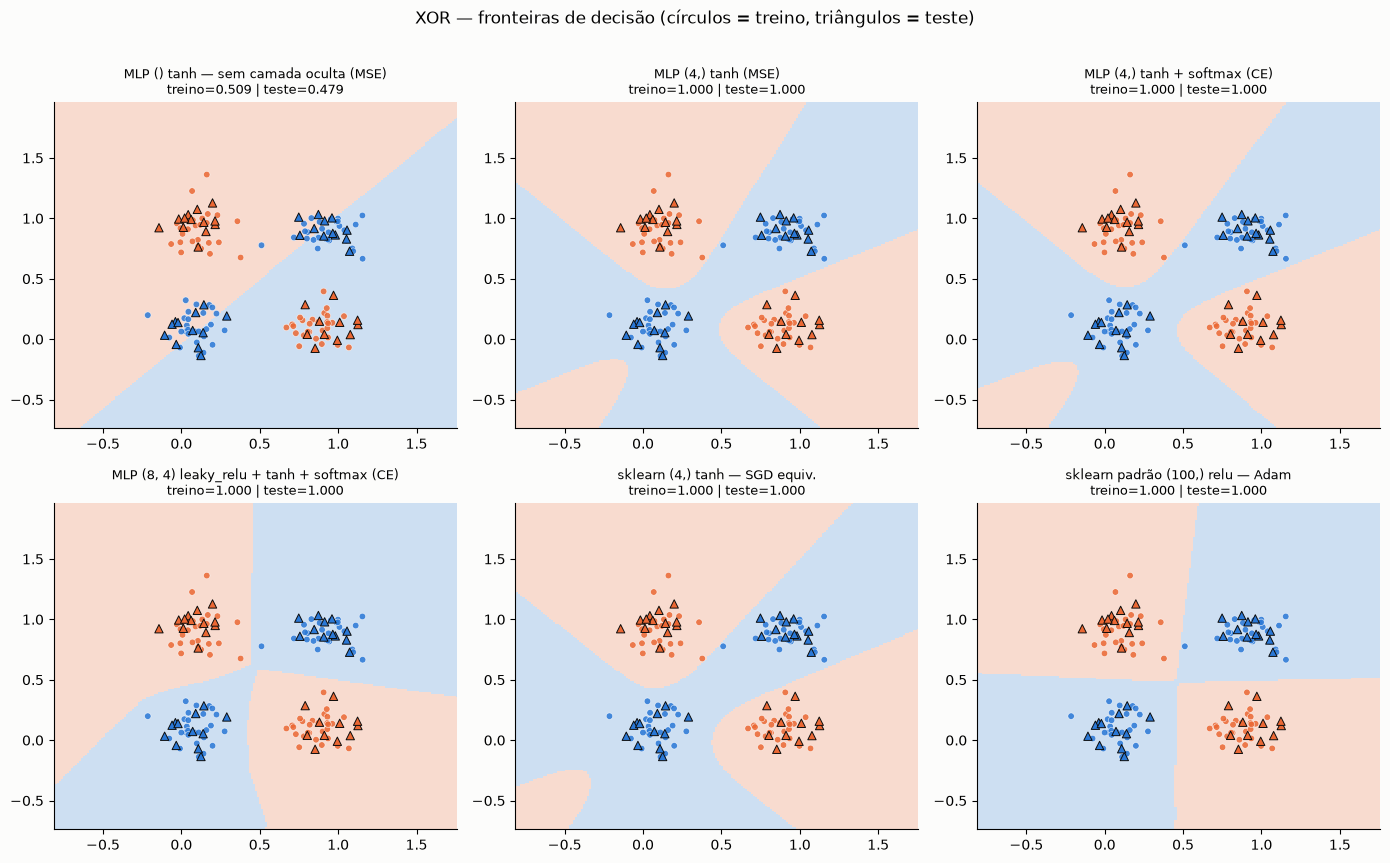

In [8]:
def create_logical_dataset(n: int = 160, func=lambda a, b: bool(a) != bool(b), random_state: int = SEED):
    X, _ = make_blobs(
        n_samples=n,
        centers=[[0.1, 0.1], [0.9, 0.1], [0.1, 0.9], [0.9, 0.9]],
        n_features=2,
        cluster_std=0.12,
        random_state=random_state,
    )
    y = np.array([func(a > 0.5, b > 0.5) for a, b in X], dtype=int) * 2 - 1
    return X, y


X_xor, y_xor = create_logical_dataset(n=160, random_state=SEED)
X_xor_tr, X_xor_te, y_xor_tr, y_xor_te = train_test_split(
    X_xor, y_xor, test_size=0.3, stratify=y_xor, random_state=SEED
)

xor_models = {
    "MLP () tanh — sem camada oculta (MSE)": MLP(
        (), "tanh", loss="mse", learning_rate=0.5, max_iter=2500, random_state=SEED
    ),
    "MLP (4,) tanh (MSE)": MLP((4,), "tanh", loss="mse", learning_rate=0.5, max_iter=2500, random_state=SEED),
    "MLP (4,) tanh + softmax (CE)": MLP(
        (4,), "tanh", loss="cross_entropy", learning_rate=0.5, max_iter=2500, random_state=SEED
    ),
    "MLP (8, 4) leaky_relu + tanh + softmax (CE)": MLP(
        (8, 4),
        ["leaky_relu", "tanh", "softmax"],
        loss="cross_entropy",
        learning_rate=0.3,
        max_iter=2500,
        random_state=SEED,
    ),
    "sklearn (4,) tanh — SGD equiv.": sklearn_equivalent((4,), "tanh", 0.5, 2500, len(X_xor_tr)),
    "sklearn padrão (100,) relu — Adam": MLPClassifier(max_iter=2500, random_state=SEED),
}

xor_results = evaluate_holdout(xor_models, X_xor_tr, y_xor_tr, X_xor_te, y_xor_te)

fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for ax, (name, res) in zip(axes.ravel(), xor_results.items()):
    plot_decision_regions(res["model"], X_xor_tr, y_xor_tr, ax, X_test=X_xor_te, y_test=y_xor_te)
    ax.set_title(f"{name}\ntreino={res['acc_train']:.3f} | teste={res['acc_test']:.3f}", fontsize=9)
fig.suptitle("XOR — fronteiras de decisão (círculos = treino, triângulos = teste)", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

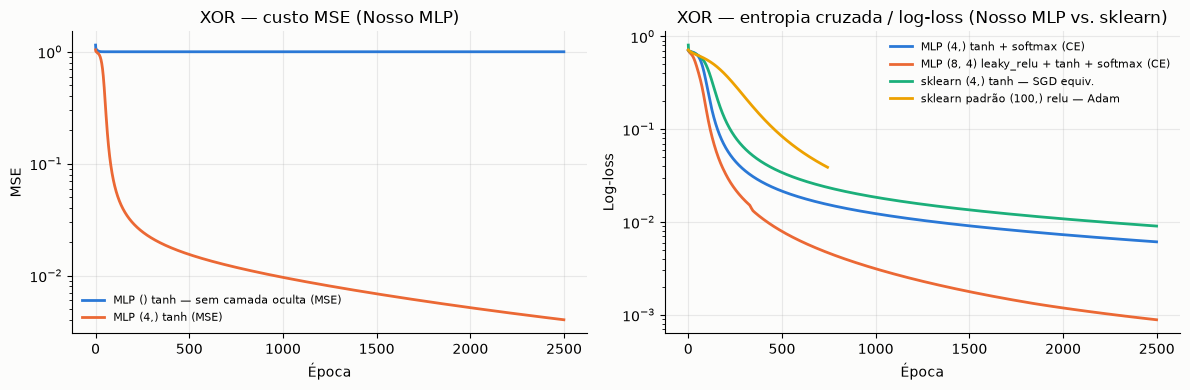

XOR (4,) relu       (15 seeds): acc média=0.924 ± 0.111 | mín=0.729 | travadas (<0,75)=2/15


XOR (4,) leaky_relu (15 seeds): acc média=0.925 ± 0.140 | mín=0.521 | travadas (<0,75)=2/15


XOR (4,) tanh       (15 seeds): acc média=1.000 ± 0.000 | mín=1.000 | travadas (<0,75)=0/15


In [9]:
# Curvas de custo do XOR separadas por escala (MSE vs. Entropia Cruzada / Log-Loss).
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, res in xor_results.items():
    model = res["model"]
    if isinstance(model, MLP) and model.loss == "mse":
        axes[0].plot(model.loss_curve_, label=name, linewidth=2)
    else:
        axes[1].plot(model.loss_curve_, label=name, linewidth=2)

axes[0].set_title("XOR — custo MSE (Nosso MLP)")
axes[0].set_ylabel("MSE")
axes[1].set_title("XOR — entropia cruzada / log-loss (Nosso MLP vs. sklearn)")
axes[1].set_ylabel("Log-loss")
for ax in axes:
    ax.set_xlabel("Época")
    ax.set_yscale("log")
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

# Diagnóstico de dying ReLU vs. LeakyReLU em rede pequena (4 neurônios ocultos, 15 sementes).
n_seeds = 15
for act_name in ["relu", "leaky_relu", "tanh"]:
    accs = []
    for s in range(n_seeds):
        m = MLP((4,), [act_name, "softmax"], loss="cross_entropy", learning_rate=0.5, max_iter=1500, random_state=s)
        m.fit(X_xor_tr, y_xor_tr)
        accs.append(accuracy_score(y_xor_te, m.predict(X_xor_te)))
    accs_arr = np.array(accs)
    n_stuck = int(np.sum(accs_arr < 0.75))
    print(
        f"XOR (4,) {act_name:10s} ({n_seeds} seeds): "
        f"acc média={accs_arr.mean():.3f} ± {accs_arr.std():.3f} | "
        f"mín={accs_arr.min():.3f} | travadas (<0,75)={n_stuck}/{n_seeds}"
    )

## 8. Teste 2 — *Blobs* multiclasse (8 classes): efeito das ativações e profundidade

*Dataset* com 8 nuvens gaussianas (inspirado na `aula05d`), dividido de forma estratificada em treino
(70%) e teste (30%) com `StandardScaler` ajustado exclusivamente no treino. Fazemos:

1. Comparação **pareada** na arquitetura `(16,) tanh` (Nosso MLP MSE, Nosso MLP CE+Softmax e sklearn SGD
   equivalente);
2. Teste de **profundidade e ativações heterogêneas** (`(32, 16)` com ReLU/Sigmoid e `(32, 16, 8)` com
   `tanh → relu → leaky_relu → softmax`);
3. Referência com o `MLPClassifier` padrão (Adam).


Modelo                                                Acc tr  Acc te   F1 te  Tempo(s)
--------------------------------------------------------------------------------------
MLP (16,) tanh (MSE)                                   0.900   0.908   0.906      0.15


MLP (16,) tanh + softmax (CE)                          0.900   0.942   0.941      0.19


MLP (32, 16) relu + relu + sigmoid (MSE)               0.907   0.908   0.907      0.29


MLP (32, 16, 8) tanh + relu + leaky + softmax (CE)     0.914   0.917   0.916      0.36


sklearn (16,) tanh — SGD equiv.                        0.900   0.900   0.900      0.36


sklearn padrão (100,) relu — Adam                      0.893   0.917   0.916      0.33


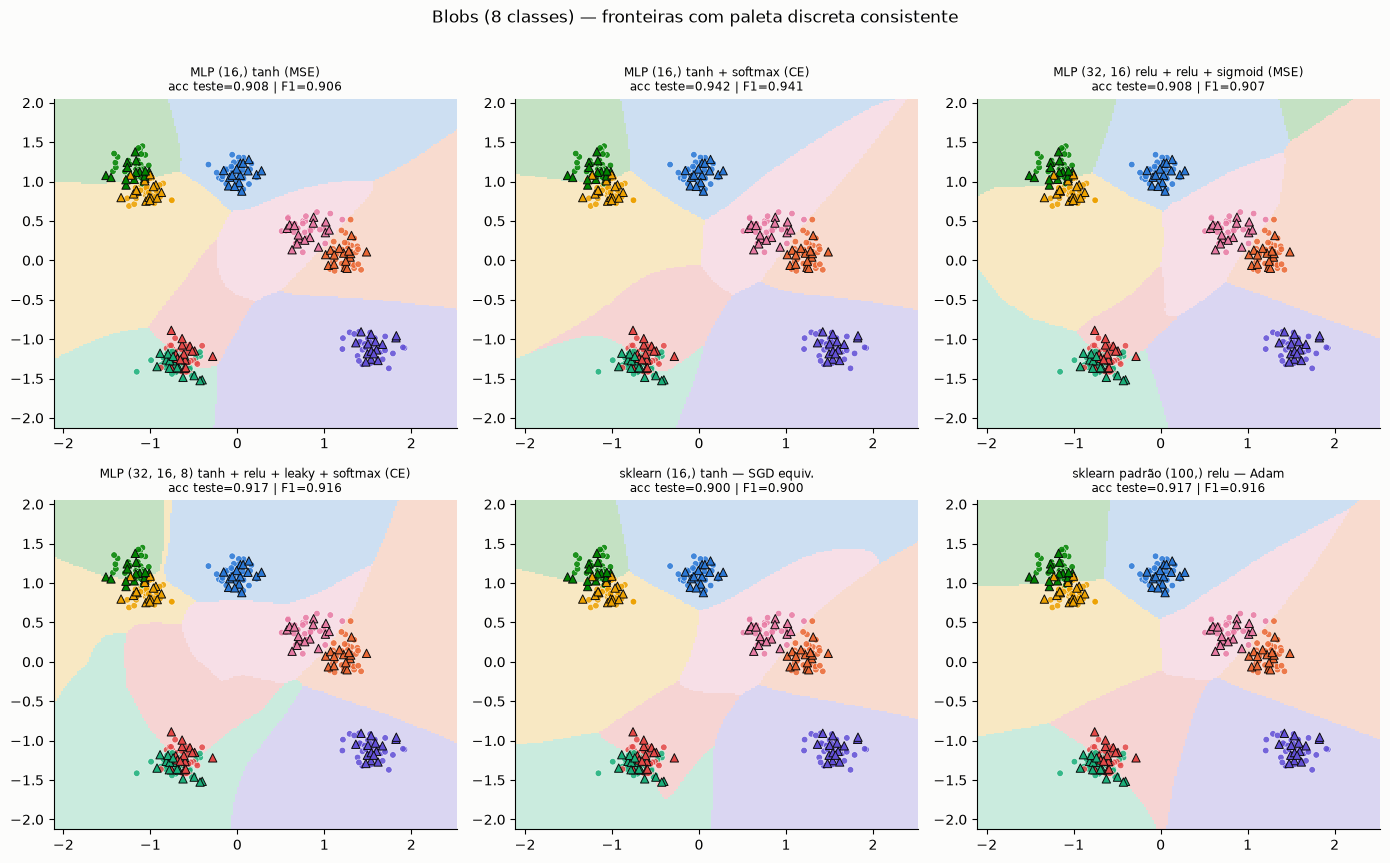

In [10]:
X_blobs, y_blobs = make_blobs(n_samples=400, centers=8, cluster_std=0.8, random_state=SEED)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X_blobs, y_blobs, test_size=0.3, stratify=y_blobs, random_state=SEED)

scaler_b = StandardScaler().fit(Xb_tr)
Xb_tr_s, Xb_te_s = scaler_b.transform(Xb_tr), scaler_b.transform(Xb_te)

blob_models = {
    "MLP (16,) tanh (MSE)": MLP((16,), "tanh", loss="mse", learning_rate=0.5, max_iter=2500, random_state=SEED),
    "MLP (16,) tanh + softmax (CE)": MLP(
        (16,), "tanh", loss="cross_entropy", learning_rate=0.5, max_iter=2500, random_state=SEED
    ),
    "MLP (32, 16) relu + relu + sigmoid (MSE)": MLP(
        (32, 16), ["relu", "relu", "sigmoid"], loss="mse", learning_rate=1.0, max_iter=2500, random_state=SEED
    ),
    "MLP (32, 16, 8) tanh + relu + leaky + softmax (CE)": MLP(
        (32, 16, 8),
        ["tanh", "relu", "leaky_relu", "softmax"],
        loss="cross_entropy",
        learning_rate=0.3,
        max_iter=2500,
        random_state=SEED,
    ),
    "sklearn (16,) tanh — SGD equiv.": sklearn_equivalent((16,), "tanh", 0.5, 2500, len(Xb_tr)),
    "sklearn padrão (100,) relu — Adam": MLPClassifier(max_iter=2500, random_state=SEED),
}

blob_results = evaluate_holdout(blob_models, Xb_tr_s, yb_tr, Xb_te_s, yb_te)

fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for ax, (name, res) in zip(axes.ravel(), blob_results.items()):
    plot_decision_regions(res["model"], Xb_tr_s, yb_tr, ax, X_test=Xb_te_s, y_test=yb_te)
    ax.set_title(f"{name}\nacc teste={res['acc_test']:.3f} | F1={res['f1_test']:.3f}", fontsize=8.5)
fig.suptitle("Blobs (8 classes) — fronteiras com paleta discreta consistente", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

## 9. Teste 3 — Iris com validação cruzada estratificada repetida (5 *folds* × 5 repetições)

Como o Iris tem apenas 150 amostras ordenadas por classe, usamos `RepeatedStratifiedKFold(5, 5)`
(25 avaliações) com `StandardScaler` **dentro de um `Pipeline`** (evitando qualquer vazamento entre
treino e validação).

Para evitar viés de seleção (*cherry-picking* da melhor configuração contra um único *baseline*), fazemos
**comparações pareadas** com a mesma arquitetura, ativação oculta e taxa de aprendizado:

- **Par A:** `(10,) tanh`, SGD *full-batch*, $\eta = 0{,}3$ (Nosso MLP MSE vs. Nosso MLP CE vs. sklearn SGD);
- **Par B:** `(10,) sigmoid`/`logistic`, SGD *full-batch*, $\eta = 1{,}0$ (Nosso MLP MSE vs. Nosso MLP CE vs. sklearn SGD);
- **Heterogêneo:** `(16, 8) relu + tanh + softmax` (exclusivo do nosso MLP) e **referência sklearn padrão (Adam)**.


Modelo                                     Acc média  Desvio  F1 média  Pior fold
---------------------------------------------------------------------------------


MLP (10,) tanh (MSE)                           0.963   0.038     0.962      0.867


MLP (10,) tanh + softmax (CE)                  0.967   0.033     0.966      0.900


sklearn (10,) tanh — SGD equiv.                0.963   0.037     0.962      0.900


MLP (10,) sigmoid (MSE)                        0.969   0.034     0.969      0.900


MLP (10,) sigmoid + softmax (CE)               0.969   0.035     0.969      0.900


sklearn (10,) logistic — SGD equiv.            0.968   0.036     0.968      0.900


MLP (16, 8) relu + tanh + softmax (CE)         0.948   0.042     0.948      0.833


sklearn padrão (100,) relu — Adam              0.951   0.044     0.951      0.867


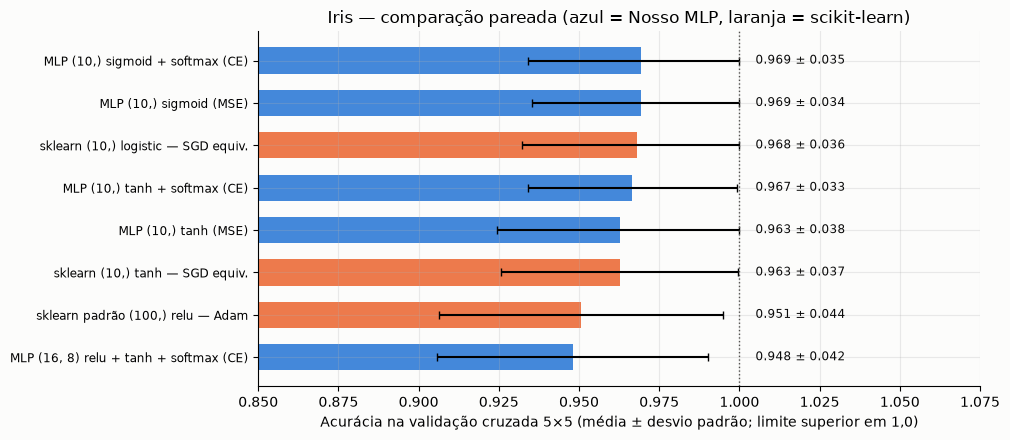

In [11]:
X_iris, y_iris = load_iris(return_X_y=True)
cv_iris = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
n_fold_train = int(len(X_iris) * 4 / 5)

iris_models = {
    "MLP (10,) tanh (MSE)": MLP((10,), "tanh", loss="mse", learning_rate=0.3, max_iter=2000, random_state=SEED),
    "MLP (10,) tanh + softmax (CE)": MLP(
        (10,), "tanh", loss="cross_entropy", learning_rate=0.3, max_iter=2000, random_state=SEED
    ),
    "sklearn (10,) tanh — SGD equiv.": sklearn_equivalent((10,), "tanh", 0.3, 2000, n_fold_train),
    "MLP (10,) sigmoid (MSE)": MLP((10,), "sigmoid", loss="mse", learning_rate=1.0, max_iter=2000, random_state=SEED),
    "MLP (10,) sigmoid + softmax (CE)": MLP(
        (10,), "sigmoid", loss="cross_entropy", learning_rate=1.0, max_iter=2000, random_state=SEED
    ),
    "sklearn (10,) logistic — SGD equiv.": sklearn_equivalent((10,), "logistic", 1.0, 2000, n_fold_train),
    "MLP (16, 8) relu + tanh + softmax (CE)": MLP(
        (16, 8), ["relu", "tanh", "softmax"], loss="cross_entropy", learning_rate=0.3, max_iter=2000, random_state=SEED
    ),
    "sklearn padrão (100,) relu — Adam": MLPClassifier(max_iter=2000, random_state=SEED),
}

iris_results: dict[str, dict] = {}
print(f"{'Modelo':42s} {'Acc média':>9s} {'Desvio':>7s} {'F1 média':>9s} {'Pior fold':>10s}")
print("-" * 81)
for name, model in iris_models.items():
    pipe = make_pipeline(StandardScaler(), model)
    cv_out = cross_validate(pipe, X_iris, y_iris, cv=cv_iris, scoring=["accuracy", "f1_macro"])
    acc_scores = cv_out["test_accuracy"]
    f1_scores = cv_out["test_f1_macro"]
    iris_results[name] = {
        "scores": acc_scores,
        "acc_mean": float(acc_scores.mean()),
        "acc_std": float(acc_scores.std()),
        "acc_min": float(acc_scores.min()),
        "f1_mean": float(f1_scores.mean()),
    }
    print(
        f"{name:42s} {acc_scores.mean():9.3f} {acc_scores.std():7.3f} {f1_scores.mean():9.3f} {acc_scores.min():10.3f}"
    )

# Gráfico de barras horizontais ordenado com dispersão (média ± 1 desvio padrão, barra superior limitada a 1,0).
ordered_iris = sorted(iris_results.items(), key=lambda kv: kv[1]["acc_mean"])
names_i = [k for k, _ in ordered_iris]
means_i = np.array([v["acc_mean"] for _, v in ordered_iris])
stds_i = np.array([v["acc_std"] for _, v in ordered_iris])
xerr_lower = stds_i
xerr_upper = np.minimum(stds_i, 1.0 - means_i)
bar_colors = [PALETTE[1] if n.startswith("sklearn") else PALETTE[0] for n in names_i]

fig, ax = plt.subplots(figsize=(10.2, 4.5))
y_pos = np.arange(len(names_i))
ax.barh(y_pos, means_i, xerr=[xerr_lower, xerr_upper], height=0.62, color=bar_colors, alpha=0.88, capsize=3)
ax.axvline(1.0, linestyle=":", color="#52514e", linewidth=1.0)
for y_idx, (m_val, s_val) in enumerate(zip(means_i, stds_i)):
    ax.text(1.005, y_idx, f"{m_val:.3f} ± {s_val:.3f}", va="center", fontsize=8.5, color="#0b0b0b")
ax.set_yticks(y_pos)
ax.set_yticklabels(names_i, fontsize=8.5)
ax.set_xlim(0.85, 1.075)
ax.set_xlabel("Acurácia na validação cruzada 5×5 (média ± desvio padrão; limite superior em 1,0)")
ax.set_title("Iris — comparação pareada (azul = Nosso MLP, laranja = scikit-learn)")
plt.tight_layout()
plt.show()

## 10. Teste 4 — Digits (64 atributos, 10 classes): escala, regularização e análise de erros

Imagens $8\times 8$ de dígitos manuscritos (`1.797` amostras, `10` classes). Além do *holdout*
estratificado (70%/30%) com comparação pareada — inclusive testando o efeito de regularização L2 +
momento — avaliamos:

1. **Curvas de convergência na mesma escala** (*log-loss* do nosso MLP com `cross_entropy` sobreposto ao
   *log-loss* do `MLPClassifier`);
2. **Concordância preditiva** entre nosso MLP (`CE + Softmax`) e o `sklearn SGD equiv.`;
3. **Validação cruzada estratificada (5 folds)** para confirmar que o resultado não depende de um único *split*;
4. **Matriz de confusão** e inspeção visual dos **dígitos classificados incorretamente**.


In [12]:
X_dig, y_dig = load_digits(return_X_y=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(X_dig, y_dig, test_size=0.3, stratify=y_dig, random_state=SEED)
scaler_d = StandardScaler().fit(Xd_tr)
Xd_tr_s, Xd_te_s = scaler_d.transform(Xd_tr), scaler_d.transform(Xd_te)

digit_models = {
    "MLP (64,) tanh (MSE)": MLP((64,), "tanh", loss="mse", learning_rate=0.2, max_iter=1200, random_state=SEED),
    "MLP (64,) tanh + softmax (CE)": MLP(
        (64,), "tanh", loss="cross_entropy", learning_rate=0.2, max_iter=1200, random_state=SEED
    ),
    "sklearn (64,) tanh — SGD equiv.": sklearn_equivalent((64,), "tanh", 0.2, 1200, len(Xd_tr)),
    "MLP (64,) tanh + softmax (CE, mom=0.9, L2=1e-2)": MLP(
        (64,),
        "tanh",
        loss="cross_entropy",
        learning_rate=0.1,
        max_iter=600,
        alpha=1e-2,
        momentum=0.9,
        random_state=SEED,
    ),
    "sklearn (64,) tanh — SGD + mom=0.9 + L2=1e-2": sklearn_equivalent(
        (64,), "tanh", 0.1, 600, len(Xd_tr), alpha=1e-2, momentum=0.9
    ),
    "MLP (64, 32) relu + tanh + softmax (CE)": MLP(
        (64, 32), ["relu", "tanh", "softmax"], loss="cross_entropy", learning_rate=0.2, max_iter=1200, random_state=SEED
    ),
    "sklearn padrão (100,) relu — Adam": MLPClassifier(max_iter=1200, random_state=SEED),
}

digit_results = evaluate_holdout(digit_models, Xd_tr_s, yd_tr, Xd_te_s, yd_te)

# Concordância entre nosso MLP (CE) e sklearn SGD equivalente (mesma arquitetura e otimizador).
pred_ours = digit_results["MLP (64,) tanh + softmax (CE)"]["y_pred_test"]
pred_sk = digit_results["sklearn (64,) tanh — SGD equiv."]["y_pred_test"]
agreement = float(np.mean(pred_ours == pred_sk))
print(
    f"\nConcordância nas predições de teste (Nosso MLP CE vs. sklearn SGD equiv.): {agreement:.3f} ({int(np.sum(pred_ours == pred_sk))}/{len(yd_te)})"
)

# Validação cruzada estratificada de 5 folds nos modelos principais do Digits.
cv_dig = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
n_dig_fold = int(len(X_dig) * 4 / 5)
dig_cv_models = {
    "MLP (64,) tanh (MSE)": MLP((64,), "tanh", loss="mse", learning_rate=0.2, max_iter=1000, random_state=SEED),
    "MLP (64,) tanh + softmax (CE)": MLP(
        (64,), "tanh", loss="cross_entropy", learning_rate=0.2, max_iter=1000, random_state=SEED
    ),
    "MLP (64, 32) relu + tanh + softmax (CE)": MLP(
        (64, 32), ["relu", "tanh", "softmax"], loss="cross_entropy", learning_rate=0.2, max_iter=1000, random_state=SEED
    ),
    "sklearn (64,) tanh — SGD equiv.": sklearn_equivalent((64,), "tanh", 0.2, 1000, n_dig_fold),
    "sklearn padrão (100,) relu — Adam": MLPClassifier(max_iter=1000, random_state=SEED),
}
digit_cv_results: dict[str, dict] = {}
print(f"\nValidação cruzada 5-fold no Digits (n={len(X_dig)}):")
print(f"{'Modelo':45s} {'Acc média':>9s} {'Desvio':>7s} {'F1 média':>9s}")
print("-" * 74)
for name, model in dig_cv_models.items():
    pipe = make_pipeline(StandardScaler(), model)
    out = cross_validate(pipe, X_dig, y_dig, cv=cv_dig, scoring=["accuracy", "f1_macro"])
    digit_cv_results[name] = {
        "acc_mean": float(out["test_accuracy"].mean()),
        "acc_std": float(out["test_accuracy"].std()),
        "f1_mean": float(out["test_f1_macro"].mean()),
    }
    print(
        f"{name:45s} {out['test_accuracy'].mean():9.3f} {out['test_accuracy'].std():7.3f} {out['test_f1_macro'].mean():9.3f}"
    )

Modelo                                                Acc tr  Acc te   F1 te  Tempo(s)
--------------------------------------------------------------------------------------


MLP (64,) tanh (MSE)                                   0.998   0.978   0.978      1.26


MLP (64,) tanh + softmax (CE)                          1.000   0.976   0.976      1.10


sklearn (64,) tanh — SGD equiv.                        1.000   0.969   0.968      1.17


MLP (64,) tanh + softmax (CE, mom=0.9, L2=1e-2)        1.000   0.978   0.978      0.57


sklearn (64,) tanh — SGD + mom=0.9 + L2=1e-2           1.000   0.976   0.976      0.57


... (3 outputs left out)

MLP (64,) tanh + softmax (CE)                     0.976   0.003     0.975


MLP (64, 32) relu + tanh + softmax (CE)           0.968   0.004     0.968


sklearn (64,) tanh — SGD equiv.                   0.969   0.014     0.969


sklearn padrão (100,) relu — Adam                 0.981   0.003     0.981


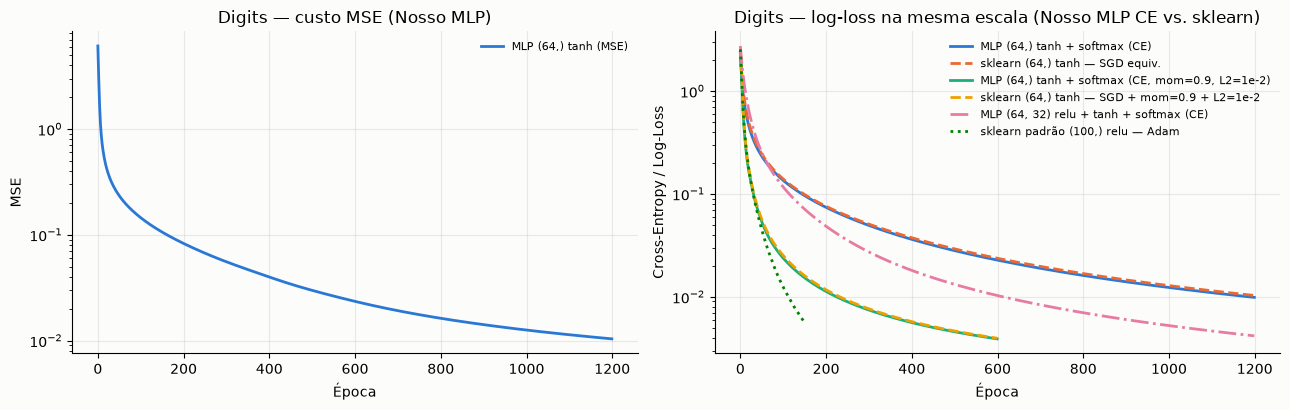

In [13]:
# Curvas de custo no Digits: à esquerda MSE; à direita log-loss na MESMA escala (Nosso MLP CE vs. sklearn).
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(digit_results["MLP (64,) tanh (MSE)"]["model"].loss_curve_, label="MLP (64,) tanh (MSE)", linewidth=2)
axes[0].set_title("Digits — custo MSE (Nosso MLP)")
axes[0].set_ylabel("MSE")

ce_curves = [
    ("MLP (64,) tanh + softmax (CE)", "-"),
    ("sklearn (64,) tanh — SGD equiv.", "--"),
    ("MLP (64,) tanh + softmax (CE, mom=0.9, L2=1e-2)", "-"),
    ("sklearn (64,) tanh — SGD + mom=0.9 + L2=1e-2", "--"),
    ("MLP (64, 32) relu + tanh + softmax (CE)", "-."),
    ("sklearn padrão (100,) relu — Adam", ":"),
]
for name, ls in ce_curves:
    axes[1].plot(digit_results[name]["model"].loss_curve_, label=name, linewidth=2, linestyle=ls)
axes[1].set_title("Digits — log-loss na mesma escala (Nosso MLP CE vs. sklearn)")
axes[1].set_ylabel("Cross-Entropy / Log-Loss")

for ax in axes:
    ax.set_xlabel("Época")
    ax.set_yscale("log")
    ax.legend(frameon=False, fontsize=7.8)
plt.tight_layout()
plt.show()

Melhor modelo probabilístico próprio: MLP (64,) tanh + softmax (CE, mom=0.9, L2=1e-2)
Erros no conjunto de teste: 12/540 (acc=0.978)


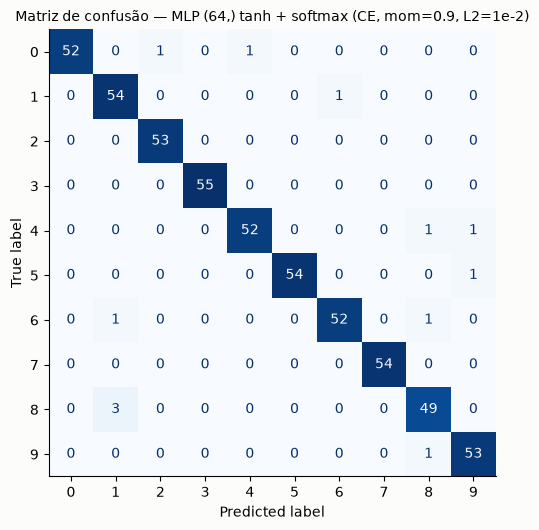

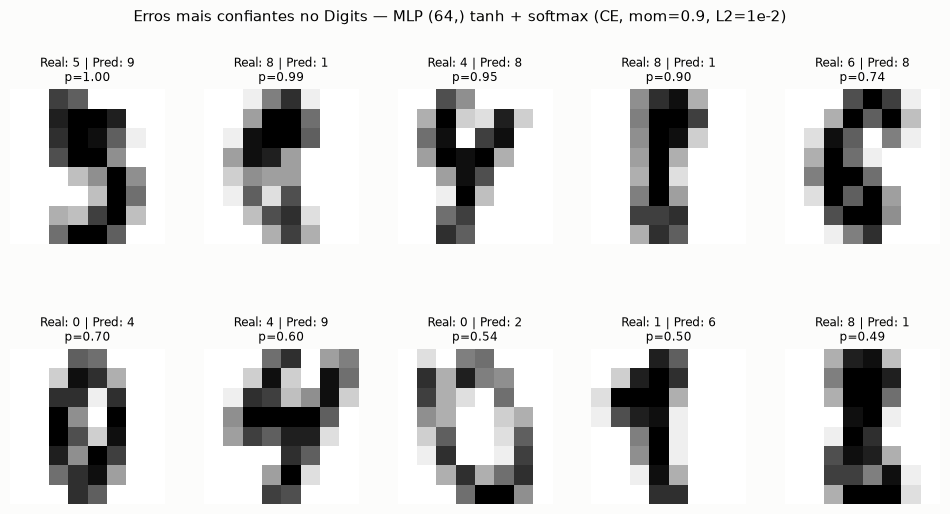

In [14]:
# Matriz de confusão e exemplos mal classificados do nosso melhor MLP com predict_proba no Digits.
best_ours_name = max(
    [
        k
        for k in digit_results
        if k.startswith("MLP") and isinstance(digit_results[k]["model"].activations_[-1], Softmax)
    ],
    key=lambda k: digit_results[k]["acc_test"],
)
best_ours = digit_results[best_ours_name]["model"]
y_pred_best = digit_results[best_ours_name]["y_pred_test"]
probs_best = best_ours.predict_proba(Xd_te_s)
errors_idx = np.where(y_pred_best != yd_te)[0]

print(f"Melhor modelo probabilístico próprio: {best_ours_name}")
print(
    f"Erros no conjunto de teste: {len(errors_idx)}/{len(yd_te)} (acc={digit_results[best_ours_name]['acc_test']:.3f})"
)

fig, ax = plt.subplots(figsize=(6.2, 5.4))
cm = confusion_matrix(yd_te, y_pred_best)
ConfusionMatrixDisplay(cm, display_labels=best_ours.classes_).plot(ax=ax, cmap="Blues", colorbar=False)
ax.grid(False)
ax.set_title(f"Matriz de confusão — {best_ours_name}", fontsize=10)
plt.tight_layout()
plt.show()

# Mostra até 10 erros ordenados por maior confiança na predição errada.
if len(errors_idx) > 0:
    conf_errors = probs_best[errors_idx, y_pred_best[errors_idx]]
    top_err = errors_idx[np.argsort(-conf_errors)[: min(10, len(errors_idx))]]
    n_show = len(top_err)
    cols = min(5, n_show)
    rows = int(np.ceil(n_show / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.4 * cols, 2.9 * rows), gridspec_kw={"hspace": 0.48, "wspace": 0.25})
    axes_flat = np.atleast_1d(axes).ravel()
    for ax_i, idx in zip(axes_flat, top_err):
        ax_i.imshow(Xd_te[idx].reshape(8, 8), cmap="gray_r")
        p_pred = probs_best[idx, y_pred_best[idx]]
        ax_i.set_title(f"Real: {yd_te[idx]} | Pred: {y_pred_best[idx]}\np={p_pred:.2f}", fontsize=8.5, pad=6)
        ax_i.axis("off")
    for ax_i in axes_flat[n_show:]:
        ax_i.axis("off")
    fig.suptitle(f"Erros mais confiantes no Digits — {best_ours_name}", fontsize=11, y=0.98)
    fig.subplots_adjust(top=0.86)
    plt.show()

## 11. Síntese quantitativa e conclusões


In [15]:
# Tabela consolidada gerada diretamente a partir dos resultados executados (sem valores copiados à mão).
summary_rows = [
    (
        "XOR (teste, 30%)",
        f"{xor_results['MLP (4,) tanh (MSE)']['acc_test']:.3f}",
        f"{xor_results['MLP (4,) tanh + softmax (CE)']['acc_test']:.3f}",
        f"{xor_results['sklearn (4,) tanh — SGD equiv.']['acc_test']:.3f}",
        f"{xor_results['sklearn padrão (100,) relu — Adam']['acc_test']:.3f}",
    ),
    (
        "Blobs 8 classes (teste)",
        f"{blob_results['MLP (16,) tanh (MSE)']['acc_test']:.3f}",
        f"{blob_results['MLP (16,) tanh + softmax (CE)']['acc_test']:.3f}",
        f"{blob_results['sklearn (16,) tanh — SGD equiv.']['acc_test']:.3f}",
        f"{blob_results['sklearn padrão (100,) relu — Adam']['acc_test']:.3f}",
    ),
    (
        "Iris tanh (CV 5×5)",
        f"{iris_results['MLP (10,) tanh (MSE)']['acc_mean']:.3f} ± {iris_results['MLP (10,) tanh (MSE)']['acc_std']:.3f}",
        f"{iris_results['MLP (10,) tanh + softmax (CE)']['acc_mean']:.3f} ± {iris_results['MLP (10,) tanh + softmax (CE)']['acc_std']:.3f}",
        f"{iris_results['sklearn (10,) tanh — SGD equiv.']['acc_mean']:.3f} ± {iris_results['sklearn (10,) tanh — SGD equiv.']['acc_std']:.3f}",
        f"{iris_results['sklearn padrão (100,) relu — Adam']['acc_mean']:.3f} ± {iris_results['sklearn padrão (100,) relu — Adam']['acc_std']:.3f}",
    ),
    (
        "Iris sigmoid/logistic (CV 5×5)",
        f"{iris_results['MLP (10,) sigmoid (MSE)']['acc_mean']:.3f} ± {iris_results['MLP (10,) sigmoid (MSE)']['acc_std']:.3f}",
        f"{iris_results['MLP (10,) sigmoid + softmax (CE)']['acc_mean']:.3f} ± {iris_results['MLP (10,) sigmoid + softmax (CE)']['acc_std']:.3f}",
        f"{iris_results['sklearn (10,) logistic — SGD equiv.']['acc_mean']:.3f} ± {iris_results['sklearn (10,) logistic — SGD equiv.']['acc_std']:.3f}",
        f"{iris_results['sklearn padrão (100,) relu — Adam']['acc_mean']:.3f} ± {iris_results['sklearn padrão (100,) relu — Adam']['acc_std']:.3f}",
    ),
    (
        "Digits (teste, holdout)",
        f"{digit_results['MLP (64,) tanh (MSE)']['acc_test']:.3f}",
        f"{digit_results['MLP (64,) tanh + softmax (CE)']['acc_test']:.3f}",
        f"{digit_results['sklearn (64,) tanh — SGD equiv.']['acc_test']:.3f}",
        f"{digit_results['sklearn padrão (100,) relu — Adam']['acc_test']:.3f}",
    ),
    (
        "Digits (CV 5-fold)",
        f"{digit_cv_results['MLP (64,) tanh (MSE)']['acc_mean']:.3f} ± {digit_cv_results['MLP (64,) tanh (MSE)']['acc_std']:.3f}",
        f"{digit_cv_results['MLP (64,) tanh + softmax (CE)']['acc_mean']:.3f} ± {digit_cv_results['MLP (64,) tanh + softmax (CE)']['acc_std']:.3f}",
        f"{digit_cv_results['sklearn (64,) tanh — SGD equiv.']['acc_mean']:.3f} ± {digit_cv_results['sklearn (64,) tanh — SGD equiv.']['acc_std']:.3f}",
        f"{digit_cv_results['sklearn padrão (100,) relu — Adam']['acc_mean']:.3f} ± {digit_cv_results['sklearn padrão (100,) relu — Adam']['acc_std']:.3f}",
    ),
]

header = f"{'Problema (comparação pareada)':32s} {'MLP MSE':>14s} {'MLP CE':>14s} {'sk SGD eq.':>14s} {'sk Adam':>14s}"
print(header)
print("-" * len(header))
for row in summary_rows:
    print(f"{row[0]:32s} {row[1]:>14s} {row[2]:>14s} {row[3]:>14s} {row[4]:>14s}")

Problema (comparação pareada)           MLP MSE         MLP CE     sk SGD eq.        sk Adam
--------------------------------------------------------------------------------------------
XOR (teste, 30%)                          1.000          1.000          1.000          1.000
Blobs 8 classes (teste)                   0.908          0.942          0.900          0.917
Iris tanh (CV 5×5)                0.963 ± 0.038  0.967 ± 0.033  0.963 ± 0.037  0.951 ± 0.044
Iris sigmoid/logistic (CV 5×5)    0.969 ± 0.034  0.969 ± 0.035  0.968 ± 0.036  0.951 ± 0.044
Digits (teste, holdout)                   0.978          0.976          0.969          0.980
Digits (CV 5-fold)                0.978 ± 0.006  0.976 ± 0.003  0.969 ± 0.014  0.981 ± 0.003


### Conclusões

#### 1. Atendimento aos requisitos e verificação matemática
- A classe `MLP` atende integralmente aos três requisitos do enunciado: permite configurar **qualquer
  quantidade de camadas** e **qualquer número de neurônios por camada** via `hidden_layer_sizes` (de `()`
  a redes profundas com larguras distintas) e **uma função de ativação por camada** via `activations`
  (`tanh`, `sigmoid`/`logistic`, `relu`, `leaky_relu`, `identity`/`linear` e `softmax`). Essa última
  flexibilidade supera o `MLPClassifier` do Scikit-Learn, que impõe uma mesma ativação para todas as
  camadas ocultas e fixa a camada de saída em *softmax*/logística.
- A **verificação numérica do gradiente** (seção 5) obteve erro relativo entre $9{,}8 \times 10^{-11}$ e
  $7{,}3 \times 10^{-10}$ nas 8 arquiteturas testadas (0 a 3 camadas ocultas, ativações mistas, *softmax*
  via *VJP* com MSE e com entropia cruzada, e regularização L2 excluindo o *bias*), confirmando a correção
  analítica do *backpropagation* independentemente de métricas de acurácia.

#### 2. Comparação pareada com o `MLPClassifier` do Scikit-Learn
- **Equivalência de otimização e desempenho:** quando comparados sob a mesma arquitetura, ativação e
  otimizador (SGD *full-batch* + entropia cruzada), nosso `MLP` e o `MLPClassifier` produzem **curvas de
  *log-loss* praticamente sobrepostas** no Digits (seção 10) — tanto em GD puro quanto com `momentum=0.9`
  e `alpha=1e-2` — e concordam em **98,5% (532/540)** das predições de teste.
- **Iris (CV 5×5 pareada):** ao parear cada ativação com seu equivalente no sklearn, os resultados são
  estatisticamente indistinguíveis dentro da dispersão dos *folds* ($\pm 0{,}033$ a $\pm 0{,}038$):
  em `tanh`, `0,963` (MSE) e `0,967` (CE) contra `0,963` (sklearn); em `sigmoid`/`logistic`, `0,969`
  (MSE e CE) contra `0,968` (sklearn). Sem esse pareamento, comparar apenas a melhor configuração própria
  contra um único *baseline* introduziria viés de seleção.
- **Digits (holdout e CV 5-fold):** no *holdout* 70/30, nosso `MLP (64,) tanh` obteve `0,978` (MSE) e
  `0,976` (CE) contra `0,969` do sklearn SGD equivalente; na CV 5-fold completa (`1.797` amostras),
  `0,978 ± 0,006` (MSE) e `0,976 ± 0,003` (CE) contra `0,969 ± 0,014` (sklearn SGD) e `0,981 ± 0,003`
  (sklearn padrão com Adam). Com `momentum=0.9` e L2 (`alpha=1e-2`) em metade das épocas (`600`), ambos
  convergiram no mesmo tempo (`0,57 s`) com acurácia `0,978` (nosso) vs. `0,976` (sklearn).
- **XOR e diagnóstico de ativações:** sem camada oculta (`()`), o perceptron fica restrito a uma fronteira
  linear (`0,479` no teste). Com camada oculta, todas as arquiteturas alcançam `1,000` em treino e teste.
  No diagnóstico com 15 sementes em rede estreita (`(4,)`), `tanh` convergiu em `15/15` sementes
  (`1,000 ± 0,000`), enquanto `relu` e `leaky_relu` ficaram presas em mínimos locais (`< 0,75`) em `2/15`
  sementes — evidenciando que, em redes muito estreitas sob GD *full-batch*, o risco de platôs não decorre
  apenas do gradiente exatamente nulo da ReLU, mas também da geometria de poucos hiperplanos lineares por partes.

#### 3. Limitações e extensões naturais
- **Otimizadores adaptativos e parada antecipada:** o `MLPClassifier` padrão (Adam + *mini-batch* +
  *early stopping* por tolerância) é ~2× a 4× mais rápido no Digits (`0,31 s` vs. `0,57–1,26 s`) porque
  interrompe o treino antes de `max_iter` e adapta o passo por parâmetro. Implementar Adam e parada
  antecipada monitorando um conjunto de validação interno é a extensão mais direta.
- **Escala computacional:** a implementação em NumPy puro (CPU) é adequada para fins didáticos e bases
  tabulares pequenas/médias, mas redes profundas sobre imagens ou texto em larga escala demandam frameworks
  com diferenciação automática e aceleração em GPU (PyTorch), tema das etapas seguintes da disciplina.
